In [1]:
# Cell 1: Import libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split, Subset
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)
print("Libraries imported successfully!")

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
NumPy version: 2.1.3
Libraries imported successfully!


In [2]:
# Cell 2: Configuration

SEED = 42
BATCH_SIZE = 64
NUM_EPOCHS = 100
LEARNING_RATE = 0.001
VALIDATION_SIZE = 5000

DATA_DIR = "./data"
MODEL_DIR = "./models"
OUTPUT_DIR = "./outputs"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Batch size:", BATCH_SIZE)
print("Epochs:", NUM_EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("Random seed:", SEED)

Device: cuda
Batch size: 64
Epochs: 100
Learning rate: 0.001
Random seed: 42


In [3]:
# Cell 3: Dataset labels

classes = (
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
)

num_classes = len(classes)

print("Number of classes:", num_classes)
print("Class names:", classes)

Number of classes: 10
Class names: ('airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


In [4]:
# Cell 4: Download CIFAR-10

# Convert images to tensors without normalizing yet.
# We will inspect the raw image distribution first.

raw_transform = transforms.ToTensor()

train_dataset_raw = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=raw_transform
)

test_dataset_raw = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=raw_transform
)

print("Training images:", len(train_dataset_raw))
print("Test images:", len(test_dataset_raw))

image, label = train_dataset_raw[0]

print("Image tensor shape:", image.shape)
print("Label index:", label)
print("Label name:", classes[label])
print("Pixel value range:", image.min().item(), "to", image.max().item())

100%|██████████| 170M/170M [50:23<00:00, 56.4kB/s]


Training images: 50000
Test images: 10000
Image tensor shape: torch.Size([3, 32, 32])
Label index: 6
Label name: frog
Pixel value range: 0.0 to 1.0


In [5]:
# Cell 5: Basic dataset inspection

train_labels = np.array(train_dataset_raw.targets)
test_labels = np.array(test_dataset_raw.targets)

print("Training dataset size:", len(train_dataset_raw))
print("Test dataset size:", len(test_dataset_raw))

print("\nTraining image shape:", train_dataset_raw[0][0].shape)
print("Training label type:", type(train_dataset_raw.targets[0]))

print("\nUnique class labels:", np.unique(train_labels))
print("Number of unique classes:", len(np.unique(train_labels)))

print("\nTraining label counts:")
print(pd.Series(train_labels).value_counts().sort_index())

Training dataset size: 50000
Test dataset size: 10000

Training image shape: torch.Size([3, 32, 32])
Training label type: <class 'int'>

Unique class labels: [0 1 2 3 4 5 6 7 8 9]
Number of unique classes: 10

Training label counts:
0    5000
1    5000
2    5000
3    5000
4    5000
5    5000
6    5000
7    5000
8    5000
9    5000
Name: count, dtype: int64


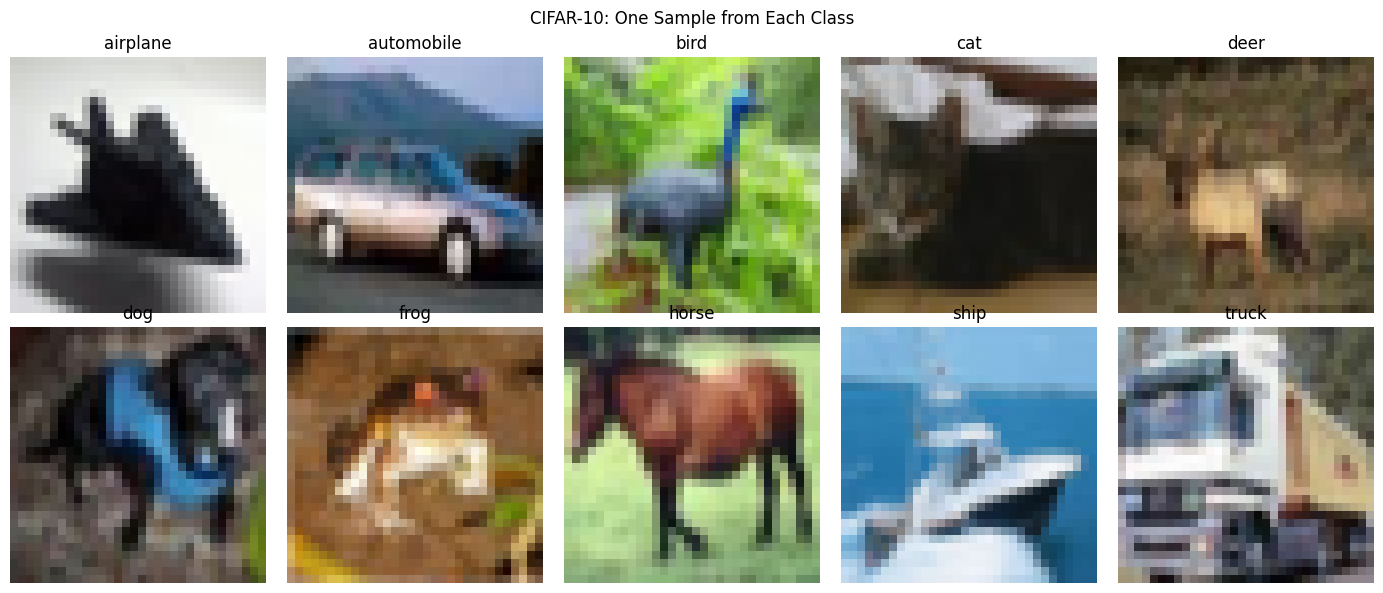

In [6]:
# Cell 6: Display sample images from every class

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for class_id, ax in enumerate(axes.flat):
    # Find the first image belonging to this class
    image_index = np.where(train_labels == class_id)[0][0]

    image, label = train_dataset_raw[image_index]

    # PyTorch uses (channels, height, width).
    # Matplotlib expects (height, width, channels).
    image_np = image.permute(1, 2, 0).numpy()

    ax.imshow(image_np)
    ax.set_title(classes[label])
    ax.axis("off")

plt.suptitle("CIFAR-10: One Sample from Each Class")
plt.tight_layout()
plt.show()

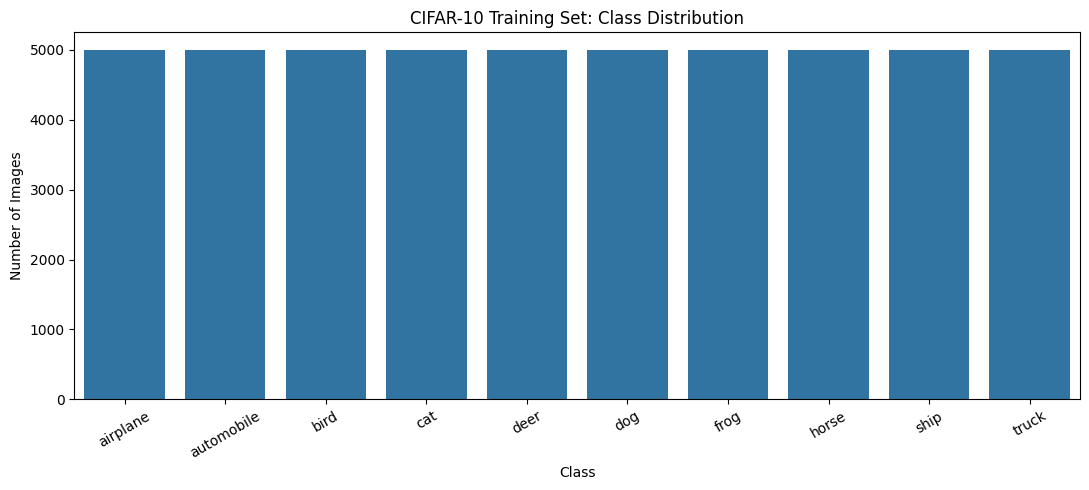

Minimum images per class: 5000
Maximum images per class: 5000


In [7]:
# Cell 7: Class distribution

class_counts = (
    pd.Series(train_labels)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(11, 5))

sns.barplot(
    x=[classes[i] for i in class_counts.index],
    y=class_counts.values
)

plt.title("CIFAR-10 Training Set: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "class_distribution.png"),
    dpi=150
)

plt.show()

print("Minimum images per class:", class_counts.min())
print("Maximum images per class:", class_counts.max())

Sample tensor shape: torch.Size([500, 3, 32, 32])
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Mean pixel value: 0.4709983766078949
Standard deviation: 0.2493579387664795


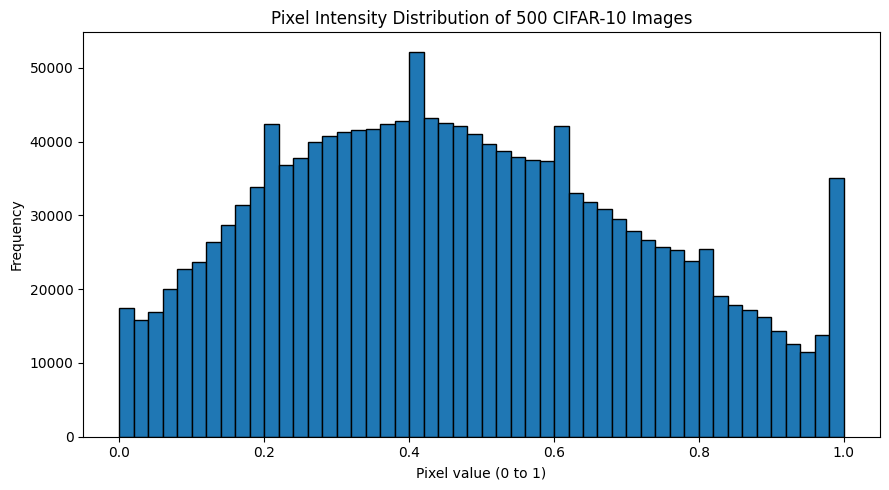

In [8]:
# Cell 8: Pixel-value analysis

sample_images = torch.stack([
    train_dataset_raw[i][0]
    for i in range(500)
])

print("Sample tensor shape:", sample_images.shape)
print("Minimum pixel value:", sample_images.min().item())
print("Maximum pixel value:", sample_images.max().item())
print("Mean pixel value:", sample_images.mean().item())
print("Standard deviation:", sample_images.std().item())

# Plot the pixel-value distribution
plt.figure(figsize=(9, 5))

plt.hist(
    sample_images.numpy().ravel(),
    bins=50,
    edgecolor="black"
)

plt.title("Pixel Intensity Distribution of 500 CIFAR-10 Images")
plt.xlabel("Pixel value (0 to 1)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "pixel_distribution.png"),
    dpi=150
)

plt.show()

In [9]:
# Cell 9: RGB channel statistics

channel_sum = torch.zeros(3)
channel_squared_sum = torch.zeros(3)
total_pixels = 0

for image, _ in train_dataset_raw:
    # image shape: [3, 32, 32]
    channel_sum += image.sum(dim=(1, 2))
    channel_squared_sum += (image ** 2).sum(dim=(1, 2))

    total_pixels += image.shape[1] * image.shape[2]

channel_mean = channel_sum / total_pixels

channel_variance = (
    channel_squared_sum / total_pixels
    - channel_mean ** 2
)

channel_std = torch.sqrt(channel_variance.clamp(min=0))

print("RGB means:", channel_mean.tolist())
print("RGB standard deviations:", channel_std.tolist())

RGB means: [0.491400808095932, 0.48215898871421814, 0.44653093814849854]
RGB standard deviations: [0.2470276653766632, 0.24348345398902893, 0.2615877091884613]


In [10]:
# Cell 10: Image transformations

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=channel_mean.tolist(),
        std=channel_std.tolist()
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=channel_mean.tolist(),
        std=channel_std.tolist()
    )
])

print("Training transformations defined.")
print("Evaluation transformations defined.")

Training transformations defined.
Evaluation transformations defined.


In [11]:
# Cell 11: Reproducible train-validation split

# Dataset instances with the appropriate transforms
train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=train_transform
)

eval_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=eval_transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=eval_transform
)

# Reproducible split of the 50,000 training images
generator = torch.Generator().manual_seed(SEED)

train_subset, val_subset = random_split(
    train_dataset,
    [45000, 5000],
    generator=generator
)

# Validation must not use random training augmentation.
val_dataset = Subset(
    eval_train_dataset,
    val_subset.indices
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Test images: 10000


In [12]:
# Cell 12: DataLoaders

train_loader = DataLoader(
    train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 704
Validation batches: 79
Test batches: 157


In [13]:
# Cell 13: Inspect one processed training batch

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

print("Batch pixel minimum:", images.min().item())
print("Batch pixel maximum:", images.max().item())

print("First 10 labels:")
print([classes[label] for label in labels[:10].tolist()])

Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])
Image dtype: torch.float32
Label dtype: torch.int64
Batch pixel minimum: -1.989254117012024
Batch pixel maximum: 2.1268014907836914
First 10 labels:
['cat', 'frog', 'automobile', 'dog', 'frog', 'automobile', 'truck', 'frog', 'cat', 'deer']


Understand the tensor dimensions

For an input batch of shape: [64, 3, 32, 32]:

Operation	        

Input images: [64, 3, 32, 32]

Convolution 1 + ReLU + pooling:	[64, 6, 14, 14]

Convolution 2 + ReLU + pooling:	[64, 16, 5, 5]

Flatten:	[64, 400]

Fully connected layer 1:	[64, 120]

Fully connected layer 2:	[64, 84]

Output:	[64, 10]

In [14]:
# Cell 14: Define the baseline CNN

class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Feature extraction
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=6,
            kernel_size=5
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )

        # Classification layers
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        # Return raw class scores (logits)
        return self.fc3(x)


model = CIFAR10CNN(num_classes=num_classes).to(device)

print(model)
print("\nDevice:", device)

CIFAR10CNN(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

Device: cuda


In [15]:
# Cell 15: Verify the forward pass

sample_images, sample_labels = next(iter(train_loader))
sample_images = sample_images.to(device)

model.eval()

with torch.no_grad():
    sample_outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Expected output shape:", (BATCH_SIZE, num_classes))

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Expected output shape: (64, 10)


In [16]:
# Cell 16: Loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", LEARNING_RATE)

Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.001


In [17]:
# Cell 17: Training and validation

import copy

best_val_loss = float("inf")
best_epoch = 0
patience = 10
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(NUM_EPOCHS):


    # Training
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_accuracy = 100.0 * train_correct / train_total


    # Validation
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_sum += loss.item() * batch_size
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = 100.0 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1:03d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

    # Save the best model according to validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        best_model_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "epoch": best_epoch,
                "model_state_dict": best_model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss
            },
            os.path.join(MODEL_DIR, "best_cifar10_cnn.pth")
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping at epoch {epoch + 1}. "
            f"Best epoch: {best_epoch}"
        )
        break

# Restore the best validation checkpoint
model.load_state_dict(best_model_state)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch [001/100] | Train Loss: 1.7475 | Train Acc: 35.03% | Val Loss: 1.5031 | Val Acc: 45.42%
Epoch [002/100] | Train Loss: 1.5070 | Train Acc: 44.63% | Val Loss: 1.3827 | Val Acc: 49.78%
Epoch [003/100] | Train Loss: 1.4105 | Train Acc: 48.79% | Val Loss: 1.3155 | Val Acc: 53.06%
Epoch [004/100] | Train Loss: 1.3468 | Train Acc: 51.34% | Val Loss: 1.2829 | Val Acc: 53.86%
Epoch [005/100] | Train Loss: 1.2969 | Train Acc: 53.16% | Val Loss: 1.2151 | Val Acc: 56.88%
Epoch [006/100] | Train Loss: 1.2578 | Train Acc: 54.59% | Val Loss: 1.1929 | Val Acc: 57.56%
Epoch [007/100] | Train Loss: 1.2268 | Train Acc: 55.84% | Val Loss: 1.1595 | Val Acc: 58.44%
Epoch [008/100] | Train Loss: 1.1963 | Train Acc: 56.91% | Val Loss: 1.1691 | Val Acc: 58.36%
Epoch [009/100] | Train Loss: 1.1744 | Train Acc: 58.11% | Val Loss: 1.1175 | Val Acc: 60.18%
Epoch [010/100] | Train Loss: 1.1489 | Train Acc: 58.95% | Val Loss: 1.0920 | Val Acc: 60.60%
Epoch [011/100] | Train Loss: 1.1347 | Train Acc: 59.42% | V

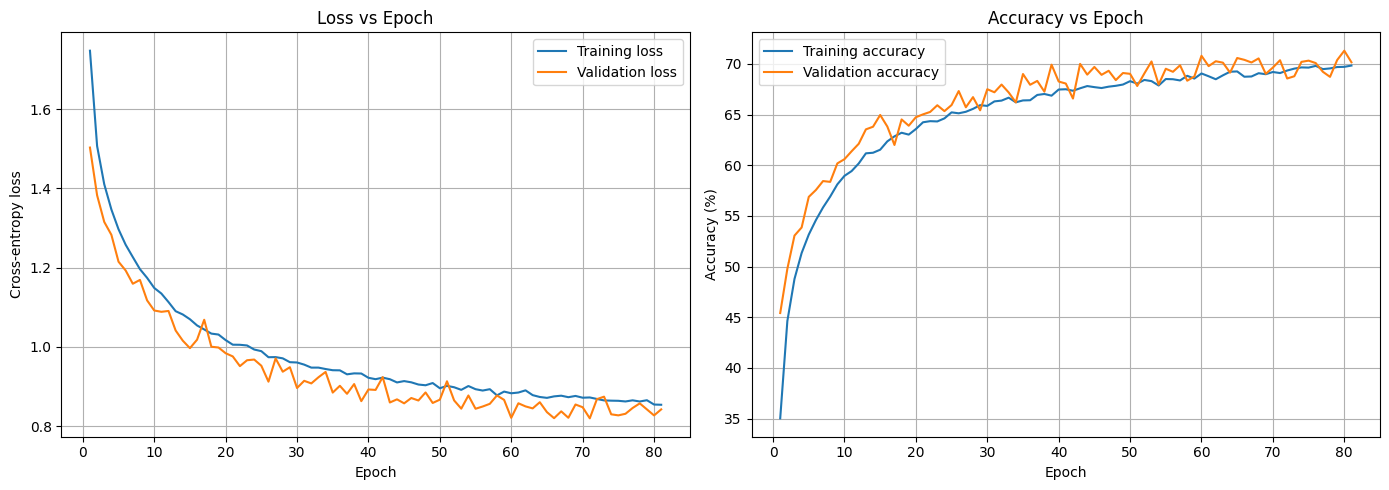

In [18]:
# Cell 18: Plot learning curves

epochs_ran = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_ran, history["train_loss"], label="Training loss")
axes[0].plot(epochs_ran, history["val_loss"], label="Validation loss")
axes[0].set_title("Loss vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs_ran, history["train_accuracy"], label="Training accuracy"
)
axes[1].plot(
    epochs_ran, history["val_accuracy"], label="Validation accuracy"
)
axes[1].set_title("Accuracy vs Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "training_curves.png"),
    dpi=150
)

plt.show()

In [19]:
# Cell 19: Get predictions on the validation set

model.eval()

val_true = []
val_pred = []
val_probs = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        val_true.extend(labels.numpy())
        val_pred.extend(predictions.cpu().numpy())
        val_probs.extend(probabilities.cpu().numpy())

val_true = np.array(val_true)
val_pred = np.array(val_pred)
val_probs = np.array(val_probs)

print("Validation examples:", len(val_true))
print(f"Validation accuracy: {accuracy_score(val_true, val_pred) * 100:.2f}%")

Validation examples: 5000
Validation accuracy: 70.36%


In [20]:
# Cell 20: Per-class evaluation

print(
    classification_report(
        val_true,
        val_pred,
        labels=list(range(num_classes)),
        target_names=list(classes),
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

    airplane      0.644     0.840     0.729       488
  automobile      0.772     0.895     0.829       512
        bird      0.630     0.628     0.629       532
         cat      0.489     0.471     0.480       471
        deer      0.685     0.628     0.656       471
         dog      0.610     0.554     0.581       514
        frog      0.771     0.777     0.774       507
       horse      0.748     0.748     0.748       500
        ship      0.913     0.706     0.796       504
       truck      0.800     0.776     0.788       501

    accuracy                          0.704      5000
   macro avg      0.706     0.702     0.701      5000
weighted avg      0.707     0.704     0.702      5000



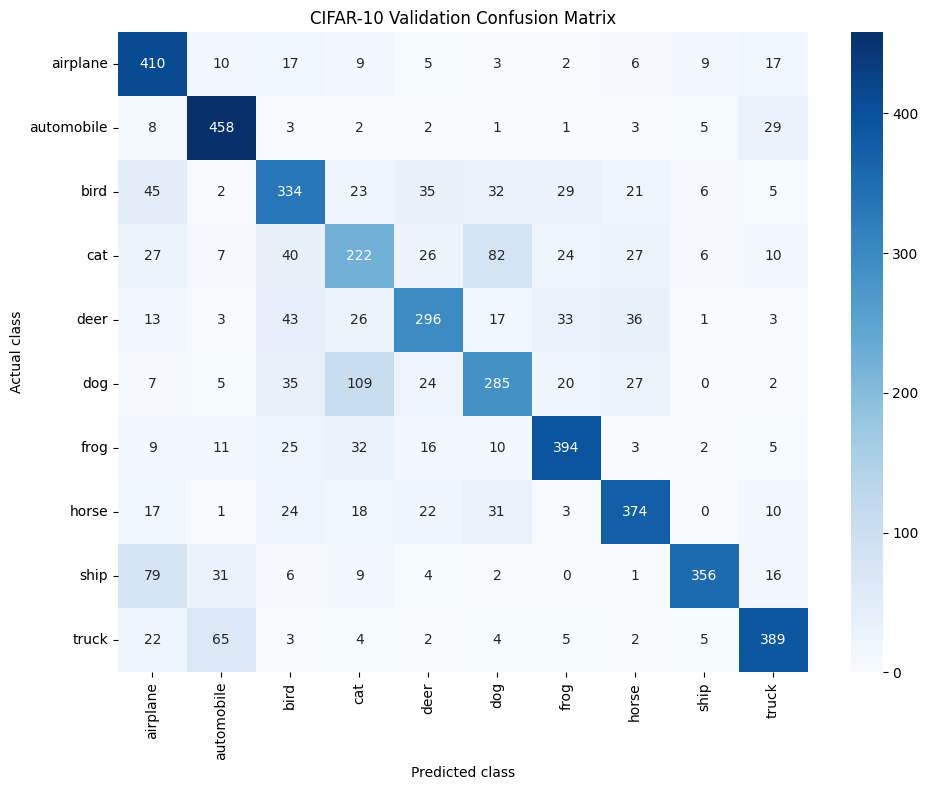

In [21]:
# Cell 21: Confusion matrix

cm = confusion_matrix(
    val_true,
    val_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("CIFAR-10 Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix_validation.png"),
    dpi=150
)

plt.show()

/tmp/ipykernel_662/3884877344.py:28: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mean = torch.tensor(channel_mean).view(3, 1, 1)
/tmp/ipykernel_662/3884877344.py:29: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  std = torch.tensor(channel_std).view(3, 1, 1)


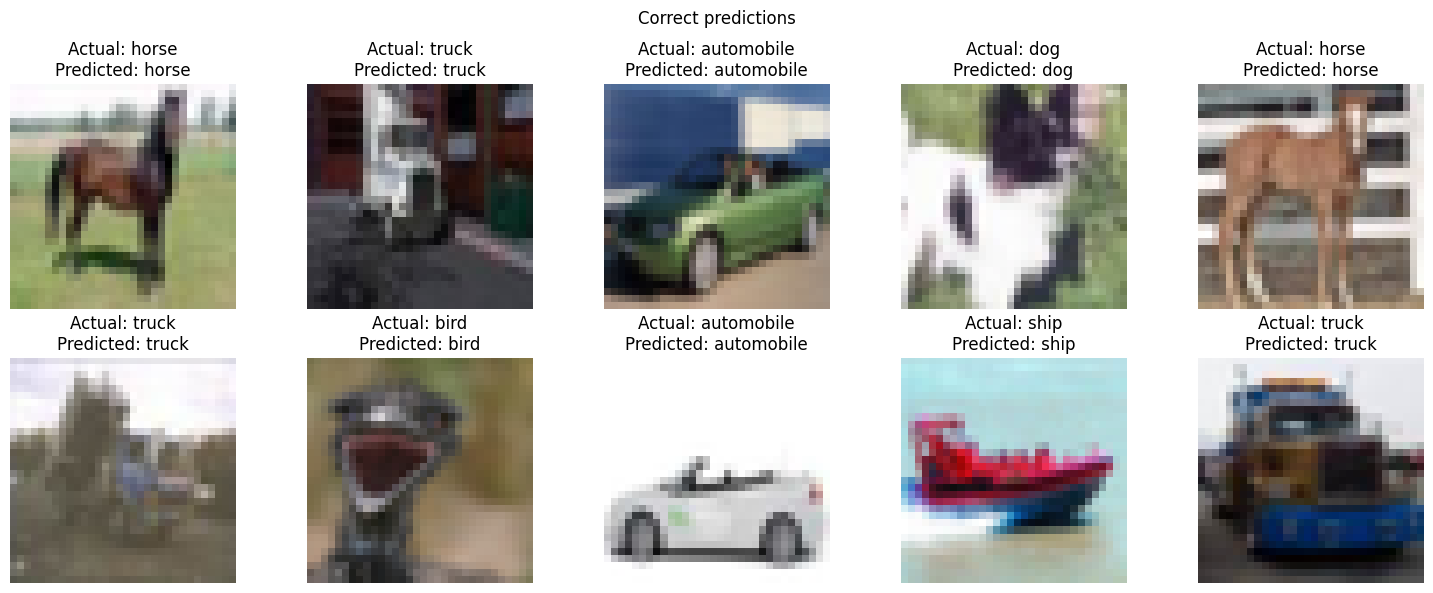

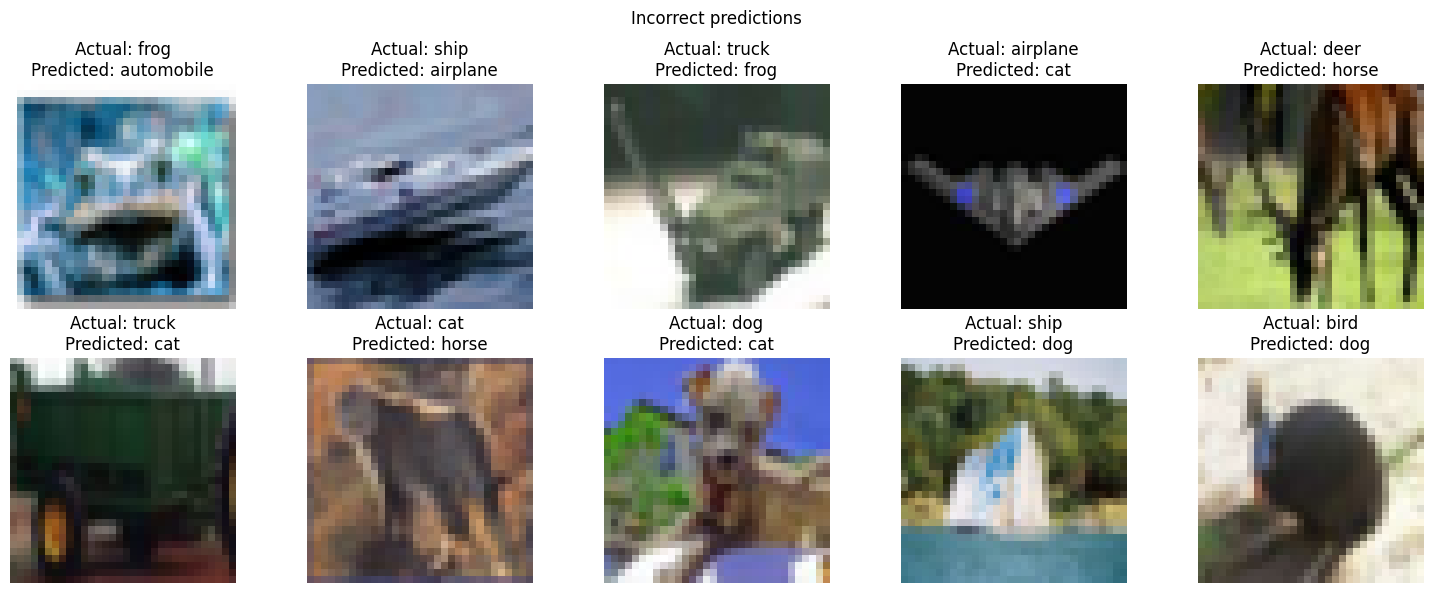

In [22]:
# Cell 22: Visualize validation predictions

def show_validation_predictions(dataset, true_labels, predicted_labels,
                                correct=True, count=10):

    if correct:
        indices = np.where(true_labels == predicted_labels)[0]
        title = "Correct predictions"
    else:
        indices = np.where(true_labels != predicted_labels)[0]
        title = "Incorrect predictions"

    if len(indices) == 0:
        print("No examples found for this category.")
        return

    indices = indices[:count]
    rows = int(np.ceil(len(indices) / 5))

    fig, axes = plt.subplots(rows, 5, figsize=(15, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, indices):
        # Validation data is normalized, so reverse normalization
        # for display using the dataset channel statistics.
        image, _ = dataset[idx]

        mean = torch.tensor(channel_mean).view(3, 1, 1)
        std = torch.tensor(channel_std).view(3, 1, 1)

        image = image * std + mean
        image = image.clamp(0, 1).permute(1, 2, 0).numpy()

        ax.imshow(image)
        ax.set_title(
            f"Actual: {classes[true_labels[idx]]}\n"
            f"Predicted: {classes[predicted_labels[idx]]}"
        )
        ax.axis("off")

    for ax in axes[len(indices):]:
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show_validation_predictions(
    val_dataset, val_true, val_pred, correct=True
)

show_validation_predictions(
    val_dataset, val_true, val_pred, correct=False
)

In [23]:
# Cell 23: Save validation results

val_report = classification_report(
    val_true,
    val_pred,
    labels=list(range(num_classes)),
    target_names=list(classes),
    output_dict=True,
    zero_division=0
)

val_report_df = pd.DataFrame(val_report).transpose()

val_report_df.to_csv(
    os.path.join(OUTPUT_DIR, "validation_classification_report.csv")
)

print("Validation report saved.")
print("Outputs directory:", OUTPUT_DIR)

Validation report saved.
Outputs directory: ./outputs


In [24]:
# Cell 24: Improved CNN architecture

class ImprovedCIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        # Convolutional feature extractor
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.15)
        )

        # Classification head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


improved_model = ImprovedCIFAR10CNN(num_classes=num_classes).to(device)

print(improved_model)
print("Device:", device)

ImprovedCIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, di

In [25]:
# Cell 25: Model sanity check

sample_images, _ = next(iter(train_loader))
sample_images = sample_images.to(device)

improved_model.eval()

with torch.no_grad():
    sample_outputs = improved_model(sample_images)

total_params = sum(
    parameter.numel()
    for parameter in improved_model.parameters()
)

trainable_params = sum(
    parameter.numel()
    for parameter in improved_model.parameters()
    if parameter.requires_grad
)

print("Input shape:", sample_images.shape)
print("Output shape:", sample_outputs.shape)
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Total parameters: 1,117,354
Trainable parameters: 1,117,354


In [26]:
# Cell 26: Improved model configuration

improved_criterion = nn.CrossEntropyLoss()

improved_optimizer = torch.optim.Adam(
    improved_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

improved_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Improved model configured.")
print("Optimizer: Adam")
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", NUM_EPOCHS)

Improved model configured.
Optimizer: Adam
Learning rate: 0.001
Maximum epochs: 100


In [27]:
# Cell 27: Train improved CNN

import copy

best_improved_val_loss = float("inf")
best_improved_epoch = 0
improved_patience = 10
improved_epochs_without_improvement = 0

best_improved_state = copy.deepcopy(improved_model.state_dict())

for epoch in range(NUM_EPOCHS):

    # Training
    improved_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        improved_optimizer.zero_grad()

        outputs = improved_model(images)
        loss = improved_criterion(outputs, labels)

        loss.backward()
        improved_optimizer.step()

        batch_n = labels.size(0)
        train_loss_sum += loss.item() * batch_n
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += batch_n

    train_loss = train_loss_sum / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Validation
    improved_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = improved_model(images)
            loss = improved_criterion(outputs, labels)

            batch_n = labels.size(0)
            val_loss_sum += loss.item() * batch_n
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += batch_n

    val_loss = val_loss_sum / val_total
    val_accuracy = 100.0 * val_correct / val_total

    improved_history["train_loss"].append(train_loss)
    improved_history["train_accuracy"].append(train_accuracy)
    improved_history["val_loss"].append(val_loss)
    improved_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1:03d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

    if val_loss < best_improved_val_loss:
        best_improved_val_loss = val_loss
        best_improved_epoch = epoch + 1
        improved_epochs_without_improvement = 0

        best_improved_state = copy.deepcopy(improved_model.state_dict())

        torch.save(
            {
                "epoch": best_improved_epoch,
                "model_state_dict": best_improved_state,
                "optimizer_state_dict": improved_optimizer.state_dict(),
                "best_val_loss": best_improved_val_loss
            },
            os.path.join(MODEL_DIR, "best_improved_cifar10_cnn.pth")
        )
    else:
        improved_epochs_without_improvement += 1

    if improved_epochs_without_improvement >= improved_patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

improved_model.load_state_dict(best_improved_state)

print("\nImproved model training completed.")
print("Best epoch:", best_improved_epoch)
print(f"Best validation loss: {best_improved_val_loss:.4f}")

Epoch [001/100] | Train Loss: 1.6957 | Train Acc: 37.37% | Val Loss: 1.3052 | Val Acc: 51.16%
Epoch [002/100] | Train Loss: 1.4168 | Train Acc: 47.53% | Val Loss: 1.1171 | Val Acc: 59.74%
Epoch [003/100] | Train Loss: 1.2650 | Train Acc: 54.36% | Val Loss: 1.0094 | Val Acc: 64.56%
Epoch [004/100] | Train Loss: 1.1766 | Train Acc: 58.01% | Val Loss: 0.8644 | Val Acc: 69.34%
Epoch [005/100] | Train Loss: 1.0982 | Train Acc: 60.83% | Val Loss: 0.8177 | Val Acc: 70.86%
Epoch [006/100] | Train Loss: 1.0399 | Train Acc: 63.34% | Val Loss: 0.8014 | Val Acc: 71.36%
Epoch [007/100] | Train Loss: 1.0019 | Train Acc: 64.62% | Val Loss: 0.7296 | Val Acc: 73.42%
Epoch [008/100] | Train Loss: 0.9680 | Train Acc: 66.19% | Val Loss: 0.7101 | Val Acc: 74.84%
Epoch [009/100] | Train Loss: 0.9458 | Train Acc: 66.95% | Val Loss: 0.7026 | Val Acc: 74.84%
Epoch [010/100] | Train Loss: 0.9105 | Train Acc: 68.25% | Val Loss: 0.6851 | Val Acc: 75.50%
Epoch [011/100] | Train Loss: 0.8911 | Train Acc: 68.87% | V

In [28]:
# Cell 28: Compare model performance

baseline_best_val_accuracy = max(history["val_accuracy"])
improved_best_val_accuracy = max(improved_history["val_accuracy"])

comparison_df = pd.DataFrame({
    "Model": ["Baseline CNN", "Improved CNN"],
    "Best Validation Accuracy (%)": [
        baseline_best_val_accuracy,
        improved_best_val_accuracy
    ],
    "Best Validation Loss": [
        best_val_loss,
        best_improved_val_loss
    ],
    "Best Epoch": [
        best_epoch,
        best_improved_epoch
    ]
})

display(comparison_df)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "model_comparison.csv"),
    index=False
)

,Model,Best Validation Accuracy (%),Best Validation Loss,Best Epoch
0,Baseline CNN,71.30,0.819818,71
1,Improved CNN,86.84,0.384724,100


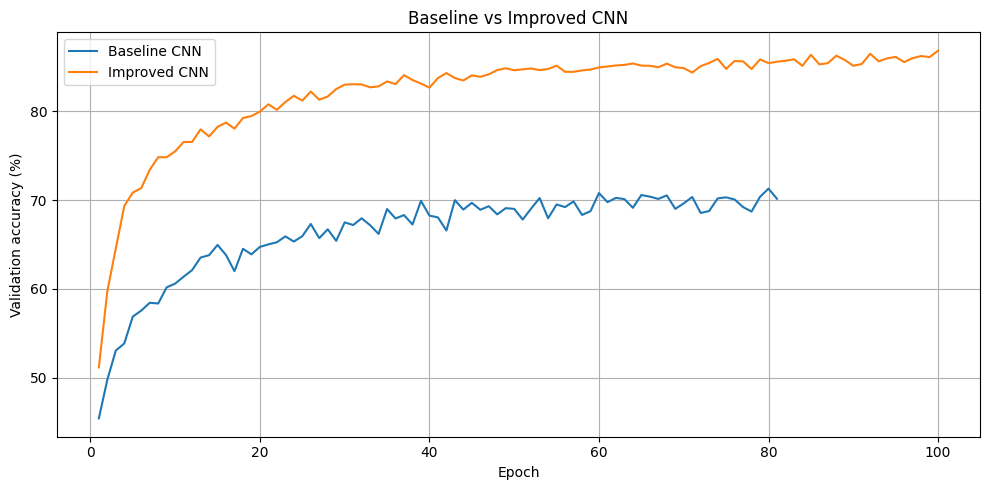

In [29]:
# Cell 29: Compare validation accuracy curves

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(history["val_accuracy"]) + 1),
    history["val_accuracy"],
    label="Baseline CNN"
)

plt.plot(
    range(1, len(improved_history["val_accuracy"]) + 1),
    improved_history["val_accuracy"],
    label="Improved CNN"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("Baseline vs Improved CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "model_comparison_accuracy.png"),
    dpi=150
)

plt.show()

In [30]:
# Cell 30: Create pretrained ResNet-18

from torchvision.models import resnet18, ResNet18_Weights

# Download pretrained ImageNet weights if not already cached
resnet_model = resnet18(weights=ResNet18_Weights.DEFAULT)

# Adapt the first convolution for small 32x32 images
resnet_model.conv1 = nn.Conv2d(
    3, 64, kernel_size=3, stride=1, padding=1, bias=False
)

# Remove the initial max-pooling operation to preserve spatial detail
resnet_model.maxpool = nn.Identity()

# Replace ImageNet's 1000-class output with 10 CIFAR-10 classes
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    num_classes
)

resnet_model = resnet_model.to(device)

print(resnet_model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 95.1MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

In [31]:
# Cell 31: Configure ResNet-18 training

resnet_criterion = nn.CrossEntropyLoss()

resnet_optimizer = torch.optim.Adam(
    [
        {
            "params": [
                p for name, p in resnet_model.named_parameters()
                if not name.startswith("fc.")
            ],
            "lr": 1e-4
        },
        {
            "params": resnet_model.fc.parameters(),
            "lr": 1e-3
        }
    ],
    weight_decay=1e-4
)

resnet_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("ResNet-18 configured.")
print("Backbone learning rate: 0.0001")
print("Classification head learning rate: 0.001")

ResNet-18 configured.
Backbone learning rate: 0.0001
Classification head learning rate: 0.001


In [32]:
# Cell 32: Train ResNet-18

import copy

best_resnet_val_loss = float("inf")
best_resnet_epoch = 0
resnet_patience = 10
resnet_epochs_without_improvement = 0

best_resnet_state = copy.deepcopy(resnet_model.state_dict())

for epoch in range(NUM_EPOCHS):

    # Training
    resnet_model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        resnet_optimizer.zero_grad()

        outputs = resnet_model(images)
        loss = resnet_criterion(outputs, labels)

        loss.backward()
        resnet_optimizer.step()

        batch_n = labels.size(0)
        train_loss_sum += loss.item() * batch_n
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += batch_n

    train_loss = train_loss_sum / train_total
    train_accuracy = 100.0 * train_correct / train_total

    # Validation
    resnet_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = resnet_criterion(outputs, labels)

            batch_n = labels.size(0)
            val_loss_sum += loss.item() * batch_n
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += batch_n

    val_loss = val_loss_sum / val_total
    val_accuracy = 100.0 * val_correct / val_total

    resnet_history["train_loss"].append(train_loss)
    resnet_history["train_accuracy"].append(train_accuracy)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1:03d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.2f}%"
    )

    if val_loss < best_resnet_val_loss:
        best_resnet_val_loss = val_loss
        best_resnet_epoch = epoch + 1
        resnet_epochs_without_improvement = 0

        best_resnet_state = copy.deepcopy(resnet_model.state_dict())

        torch.save(
            {
                "epoch": best_resnet_epoch,
                "model_state_dict": best_resnet_state,
                "optimizer_state_dict": resnet_optimizer.state_dict(),
                "best_val_loss": best_resnet_val_loss
            },
            os.path.join(MODEL_DIR, "best_resnet18_cifar10.pth")
        )
    else:
        resnet_epochs_without_improvement += 1

    if resnet_epochs_without_improvement >= resnet_patience:
        print(f"Early stopping at epoch {epoch + 1}.")
        break

resnet_model.load_state_dict(best_resnet_state)

print("\nResNet-18 training completed.")
print("Best epoch:", best_resnet_epoch)
print(f"Best validation loss: {best_resnet_val_loss:.4f}")

Epoch [001/100] | Train Loss: 0.8475 | Train Acc: 70.29% | Val Loss: 0.4869 | Val Acc: 82.98%
Epoch [002/100] | Train Loss: 0.4362 | Train Acc: 84.97% | Val Loss: 0.3791 | Val Acc: 87.16%
Epoch [003/100] | Train Loss: 0.3178 | Train Acc: 89.15% | Val Loss: 0.3087 | Val Acc: 89.62%
Epoch [004/100] | Train Loss: 0.2536 | Train Acc: 91.25% | Val Loss: 0.2679 | Val Acc: 91.18%
Epoch [005/100] | Train Loss: 0.2133 | Train Acc: 92.60% | Val Loss: 0.2851 | Val Acc: 90.68%
Epoch [006/100] | Train Loss: 0.1756 | Train Acc: 93.83% | Val Loss: 0.2822 | Val Acc: 91.46%
Epoch [007/100] | Train Loss: 0.1556 | Train Acc: 94.53% | Val Loss: 0.2680 | Val Acc: 91.76%
Epoch [008/100] | Train Loss: 0.1368 | Train Acc: 95.37% | Val Loss: 0.2598 | Val Acc: 92.08%
Epoch [009/100] | Train Loss: 0.1248 | Train Acc: 95.60% | Val Loss: 0.2321 | Val Acc: 93.32%
Epoch [010/100] | Train Loss: 0.1098 | Train Acc: 96.26% | Val Loss: 0.2679 | Val Acc: 92.64%
Epoch [011/100] | Train Loss: 0.1038 | Train Acc: 96.38% | V

In [33]:
# Cell 33: Compare the three models

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Improved CNN v2",
        "Pretrained ResNet-18"
    ],
    "Best Epoch": [
        best_epoch,
        best_improved_epoch,
        best_resnet_epoch
    ],
    "Best Validation Loss": [
        best_val_loss,
        best_improved_val_loss,
        best_resnet_val_loss
    ],
    "Best Validation Accuracy (%)": [
        max(history["val_accuracy"]),
        max(improved_history["val_accuracy"]),
        max(resnet_history["val_accuracy"])
    ]
})

display(
    comparison_df.sort_values(
        "Best Validation Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)

comparison_df.to_csv(
    os.path.join(OUTPUT_DIR, "three_model_comparison.csv"),
    index=False
)

,Model,Best Epoch,Best Validation Loss,Best Validation Accuracy (%)
0,Pretrained ResNet-18,9,0.232138,93.34
1,Improved CNN v2,100,0.384724,86.84
2,Baseline CNN,71,0.819818,71.30


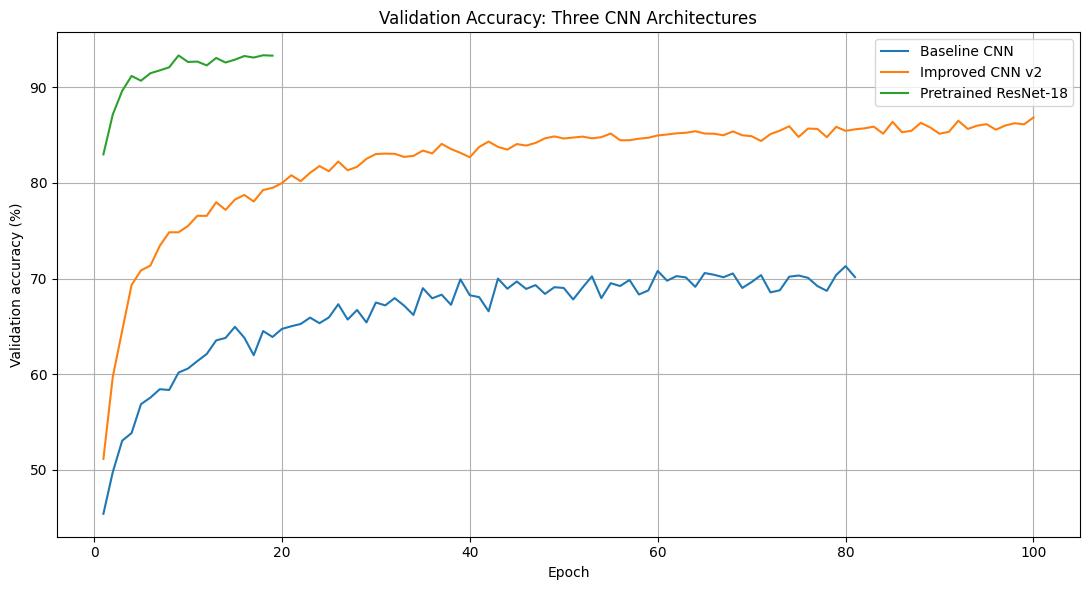

In [34]:
# Cell 34: Visual comparison of all three models

plt.figure(figsize=(11, 6))

plt.plot(
    range(1, len(history["val_accuracy"]) + 1),
    history["val_accuracy"],
    label="Baseline CNN"
)

plt.plot(
    range(1, len(improved_history["val_accuracy"]) + 1),
    improved_history["val_accuracy"],
    label="Improved CNN v2"
)

plt.plot(
    range(1, len(resnet_history["val_accuracy"]) + 1),
    resnet_history["val_accuracy"],
    label="Pretrained ResNet-18"
)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("Validation Accuracy: Three CNN Architectures")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "three_model_accuracy_comparison.png"),
    dpi=150
)

plt.show()

In [35]:
# Cell 35: ResNet-18 data loaders with ImageNet normalization

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

resnet_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

resnet_eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# Training data with augmentation
resnet_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=resnet_train_transform
)

# Training data without augmentation, for validation
resnet_eval_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=resnet_eval_transform
)

# Official test set
resnet_test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=False,
    transform=resnet_eval_transform
)

# Reuse the exact same split indices from Cell 11
resnet_train_subset = Subset(
    resnet_train_dataset,
    train_subset.indices
)

resnet_val_dataset = Subset(
    resnet_eval_train_dataset,
    val_subset.indices
)

resnet_train_loader = DataLoader(
    resnet_train_subset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("ResNet training batches:", len(resnet_train_loader))
print("ResNet validation batches:", len(resnet_val_loader))
print("ResNet test batches:", len(resnet_test_loader))

ResNet training batches: 704
ResNet validation batches: 79
ResNet test batches: 157


In [36]:
# Cell 36: Reusable model evaluation function

def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_samples += batch_size

            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    average_loss = total_loss / total_samples
    accuracy = total_correct / total_samples

    return {
        "test_loss": average_loss,
        "test_accuracy": accuracy,
        "true_labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "probabilities": np.array(all_probabilities)
    }

print("Evaluation function defined successfully.")

Evaluation function defined successfully.


In [37]:
# Cell 37: Evaluate all three models on the test set

baseline_results = evaluate_model(
    model, test_loader, criterion, device
)

improved_results = evaluate_model(
    improved_model, test_loader, improved_criterion, device
)

resnet_results = evaluate_model(
    resnet_model, resnet_test_loader, resnet_criterion, device
)

print("BASELINE CNN")
print(f"Test Loss: {baseline_results['test_loss']:.4f}")
print(f"Test Accuracy: {baseline_results['test_accuracy'] * 100:.2f}%")

print("\nIMPROVED CNN")
print(f"Test Loss: {improved_results['test_loss']:.4f}")
print(f"Test Accuracy: {improved_results['test_accuracy'] * 100:.2f}%")

print("\nPRETRAINED RESNET-18")
print(f"Test Loss: {resnet_results['test_loss']:.4f}")
print(f"Test Accuracy: {resnet_results['test_accuracy'] * 100:.2f}%")

BASELINE CNN
Test Loss: 0.8303
Test Accuracy: 70.98%

IMPROVED CNN
Test Loss: 0.4186
Test Accuracy: 85.66%

PRETRAINED RESNET-18
Test Loss: 0.2674
Test Accuracy: 92.12%


In [38]:
# Cell 38: Compare final test performance

test_comparison = pd.DataFrame([
    {
        "Model": "Baseline CNN",
        "Test Loss": baseline_results["test_loss"],
        "Test Accuracy (%)": baseline_results["test_accuracy"] * 100
    },
    {
        "Model": "Improved CNN",
        "Test Loss": improved_results["test_loss"],
        "Test Accuracy (%)": improved_results["test_accuracy"] * 100
    },
    {
        "Model": "Pretrained ResNet-18",
        "Test Loss": resnet_results["test_loss"],
        "Test Accuracy (%)": resnet_results["test_accuracy"] * 100
    }
])

test_comparison = test_comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

display(test_comparison.round(4))

test_comparison.to_csv(
    os.path.join(OUTPUT_DIR, "final_test_comparison.csv"),
    index=False
)

print("Saved final test comparison.")

,Model,Test Loss,Test Accuracy (%)
0,Pretrained ResNet-18,0.2674,92.12
1,Improved CNN,0.4186,85.66
2,Baseline CNN,0.8303,70.98


Saved final test comparison.


In [39]:
# Cell 39: Classification reports for all three models

results_by_model = {
    "Baseline CNN": baseline_results,
    "Improved CNN": improved_results,
    "Pretrained ResNet-18": resnet_results
}

for model_name, results in results_by_model.items():
    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    print(classification_report(
        results["true_labels"],
        results["predictions"],
        labels=list(range(num_classes)),
        target_names=classes,
        digits=4,
        zero_division=0
    ))


Baseline CNN
              precision    recall  f1-score   support

    airplane     0.6731    0.8030    0.7323      1000
  automobile     0.7551    0.8970    0.8199      1000
        bird     0.6272    0.5990    0.6128      1000
         cat     0.5295    0.4940    0.5111      1000
        deer     0.7311    0.6580    0.6926      1000
         dog     0.6170    0.6010    0.6089      1000
        frog     0.7707    0.7900    0.7802      1000
       horse     0.7441    0.7590    0.7515      1000
        ship     0.8701    0.7100    0.7819      1000
       truck     0.7902    0.7870    0.7886      1000

    accuracy                         0.7098     10000
   macro avg     0.7108    0.7098    0.7080     10000
weighted avg     0.7108    0.7098    0.7080     10000


Improved CNN
              precision    recall  f1-score   support

    airplane     0.8413    0.8850    0.8626      1000
  automobile     0.9229    0.9450    0.9338      1000
        bird     0.8362    0.7660    0.7996      1

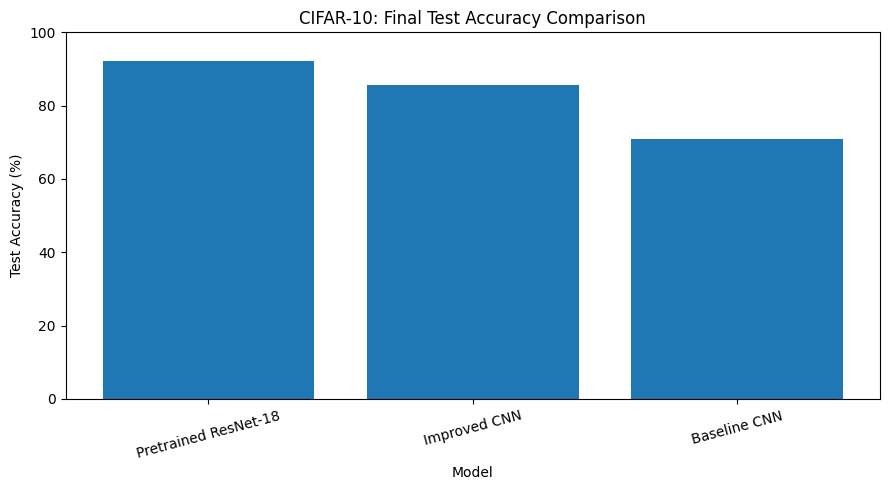

In [40]:
# Cell 40: Final test accuracy chart

plt.figure(figsize=(9, 5))

plt.bar(
    test_comparison["Model"],
    test_comparison["Test Accuracy (%)"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Model")
plt.title("CIFAR-10: Final Test Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_test_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

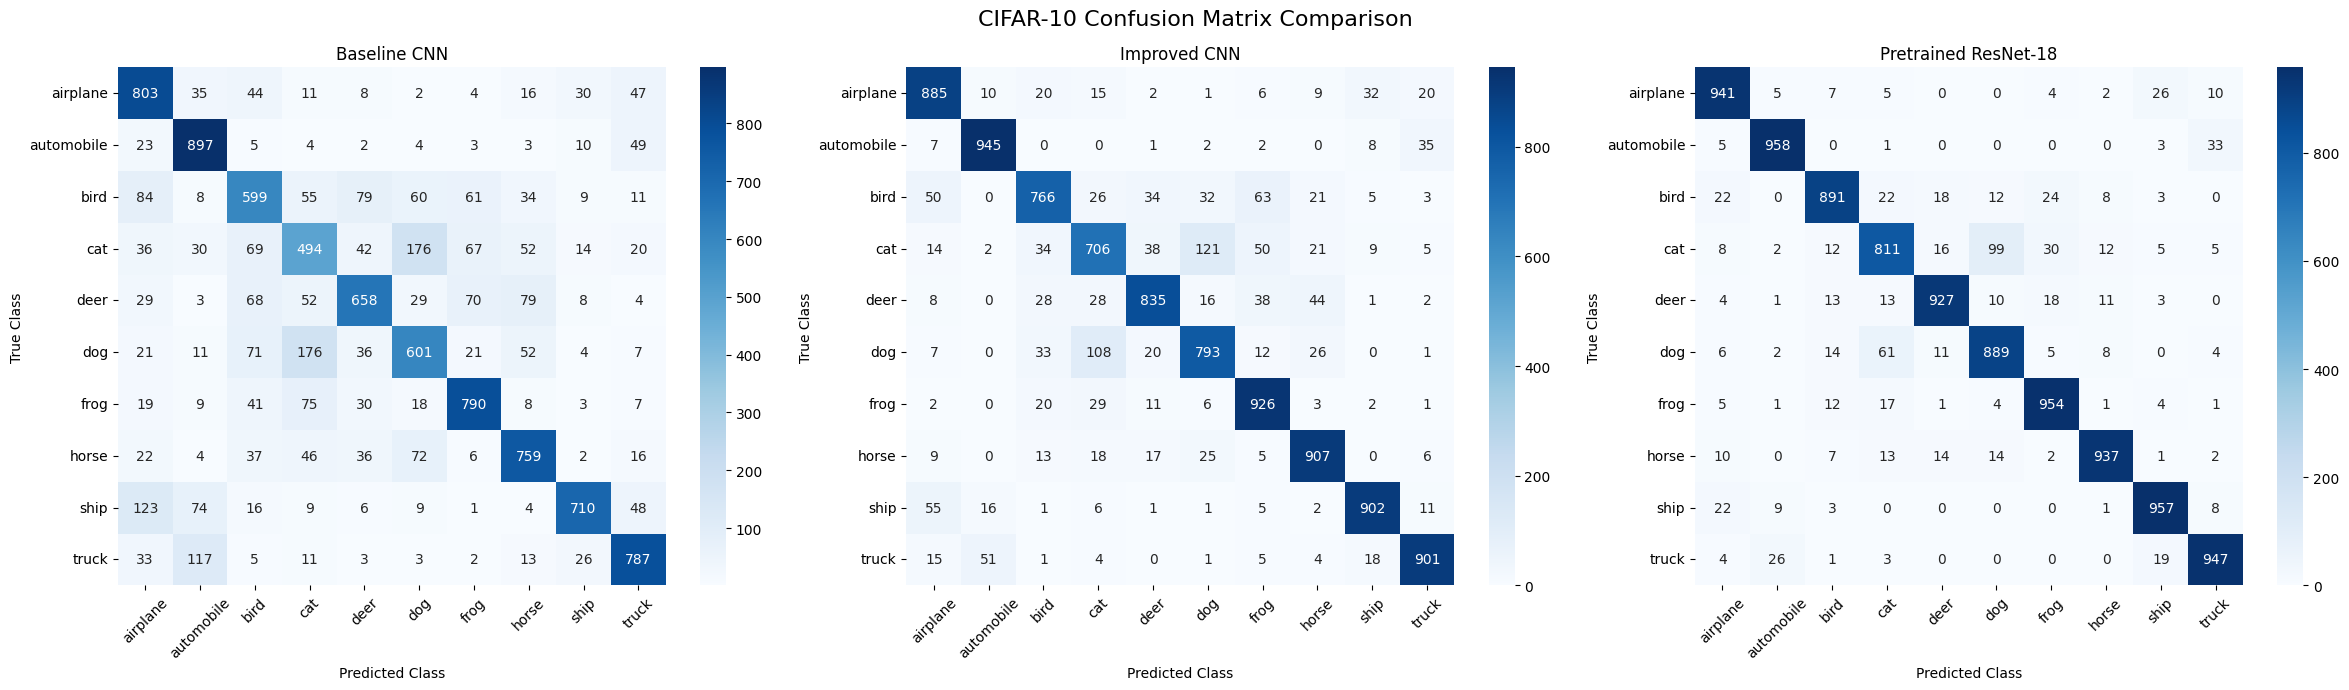

In [41]:
# Cell 41: Confusion matrices for all three models

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for ax, (model_name, results) in zip(axes, results_by_model.items()):
    cm = confusion_matrix(
        results["true_labels"],
        results["predictions"],
        labels=list(range(num_classes))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("CIFAR-10 Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "three_model_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
# Cell 42: Per-class accuracy comparison

per_class_data = []

for model_name, results in results_by_model.items():
    true_labels = results["true_labels"]
    predictions = results["predictions"]

    for class_id, class_name in enumerate(classes):
        mask = true_labels == class_id

        class_accuracy = np.mean(
            predictions[mask] == true_labels[mask]
        ) * 100

        per_class_data.append({
            "Model": model_name,
            "Class": class_name,
            "Accuracy (%)": class_accuracy
        })

per_class_df = pd.DataFrame(per_class_data)

display(
    per_class_df.pivot(
        index="Class",
        columns="Model",
        values="Accuracy (%)"
    ).round(2)
)

per_class_df.to_csv(
    os.path.join(OUTPUT_DIR, "per_class_accuracy.csv"),
    index=False
)

Model,Baseline CNN,Improved CNN,Pretrained ResNet-18
Class,,,
airplane,80.3,88.5,94.1
automobile,89.7,94.5,95.8
bird,59.9,76.6,89.1
cat,49.4,70.6,81.1
deer,65.8,83.5,92.7
dog,60.1,79.3,88.9
frog,79.0,92.6,95.4
horse,75.9,90.7,93.7
ship,71.0,90.2,95.7


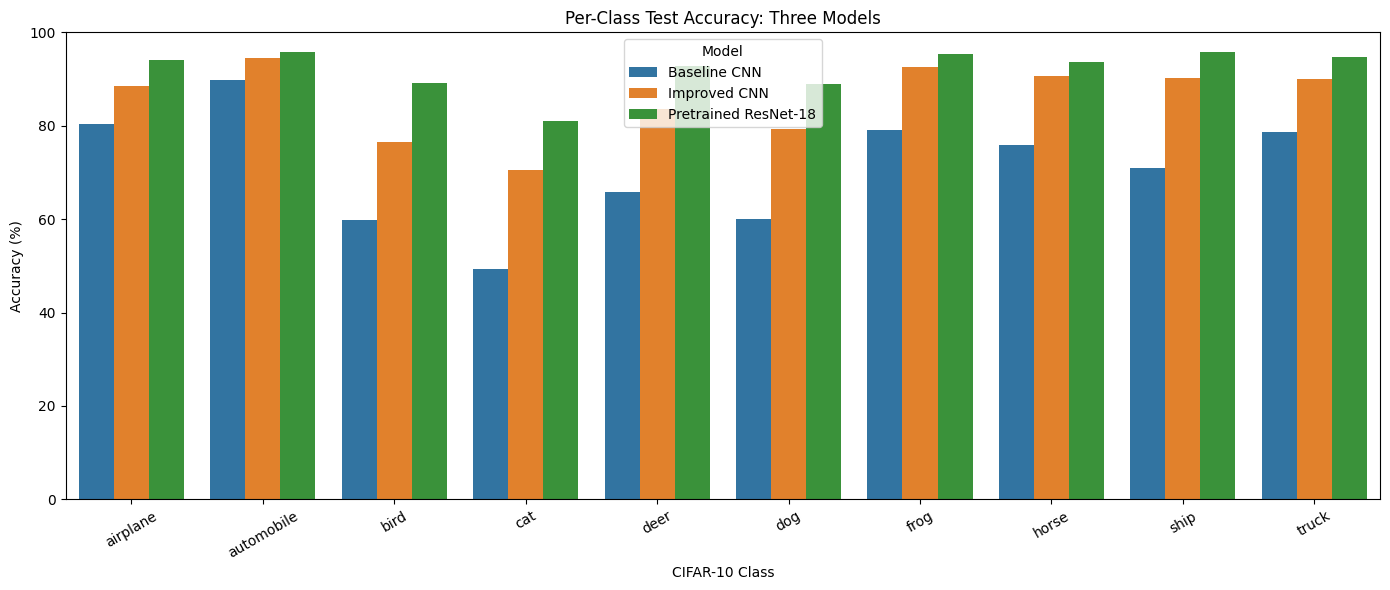

In [43]:
# Cell 43: Per-class accuracy chart

plt.figure(figsize=(14, 6))

sns.barplot(
    data=per_class_df,
    x="Class",
    y="Accuracy (%)",
    hue="Model"
)

plt.title("Per-Class Test Accuracy: Three Models")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "per_class_accuracy_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
# Cell 44: Grad-CAM implementation

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer

        self.activations = None
        self.gradients = None

        self.forward_hook = target_layer.register_forward_hook(
            self.save_activations
        )

        self.backward_hook = target_layer.register_full_backward_hook(
            self.save_gradients
        )

    def save_activations(self, module, inputs, output):
        self.activations = output

    def save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, image_tensor, class_index=None):
        self.model.eval()
        self.model.zero_grad(set_to_none=True)

        logits = self.model(image_tensor)

        if class_index is None:
            class_index = logits.argmax(dim=1).item()

        score = logits[:, class_index].sum()
        score.backward()

        # Average gradients across the spatial dimensions
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)

        # Weighted sum of feature-map activations
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = F.relu(cam)

        # Resize heatmap to the original image dimensions
        cam = F.interpolate(
            cam,
            size=image_tensor.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().cpu().numpy()

        # Normalize the heatmap to the range [0, 1]
        cam_min, cam_max = cam.min(), cam.max()
        cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

        return cam, class_index

    def close(self):
        self.forward_hook.remove()
        self.backward_hook.remove()


print("Grad-CAM class defined successfully.")

Grad-CAM class defined successfully.


In [45]:
# Cell 45: Initialize Grad-CAM for ResNet-18

gradcam = GradCAM(
    model=resnet_model,
    target_layer=resnet_model.layer4[-1]
)

print("Grad-CAM initialized for ResNet-18.")

Grad-CAM initialized for ResNet-18.


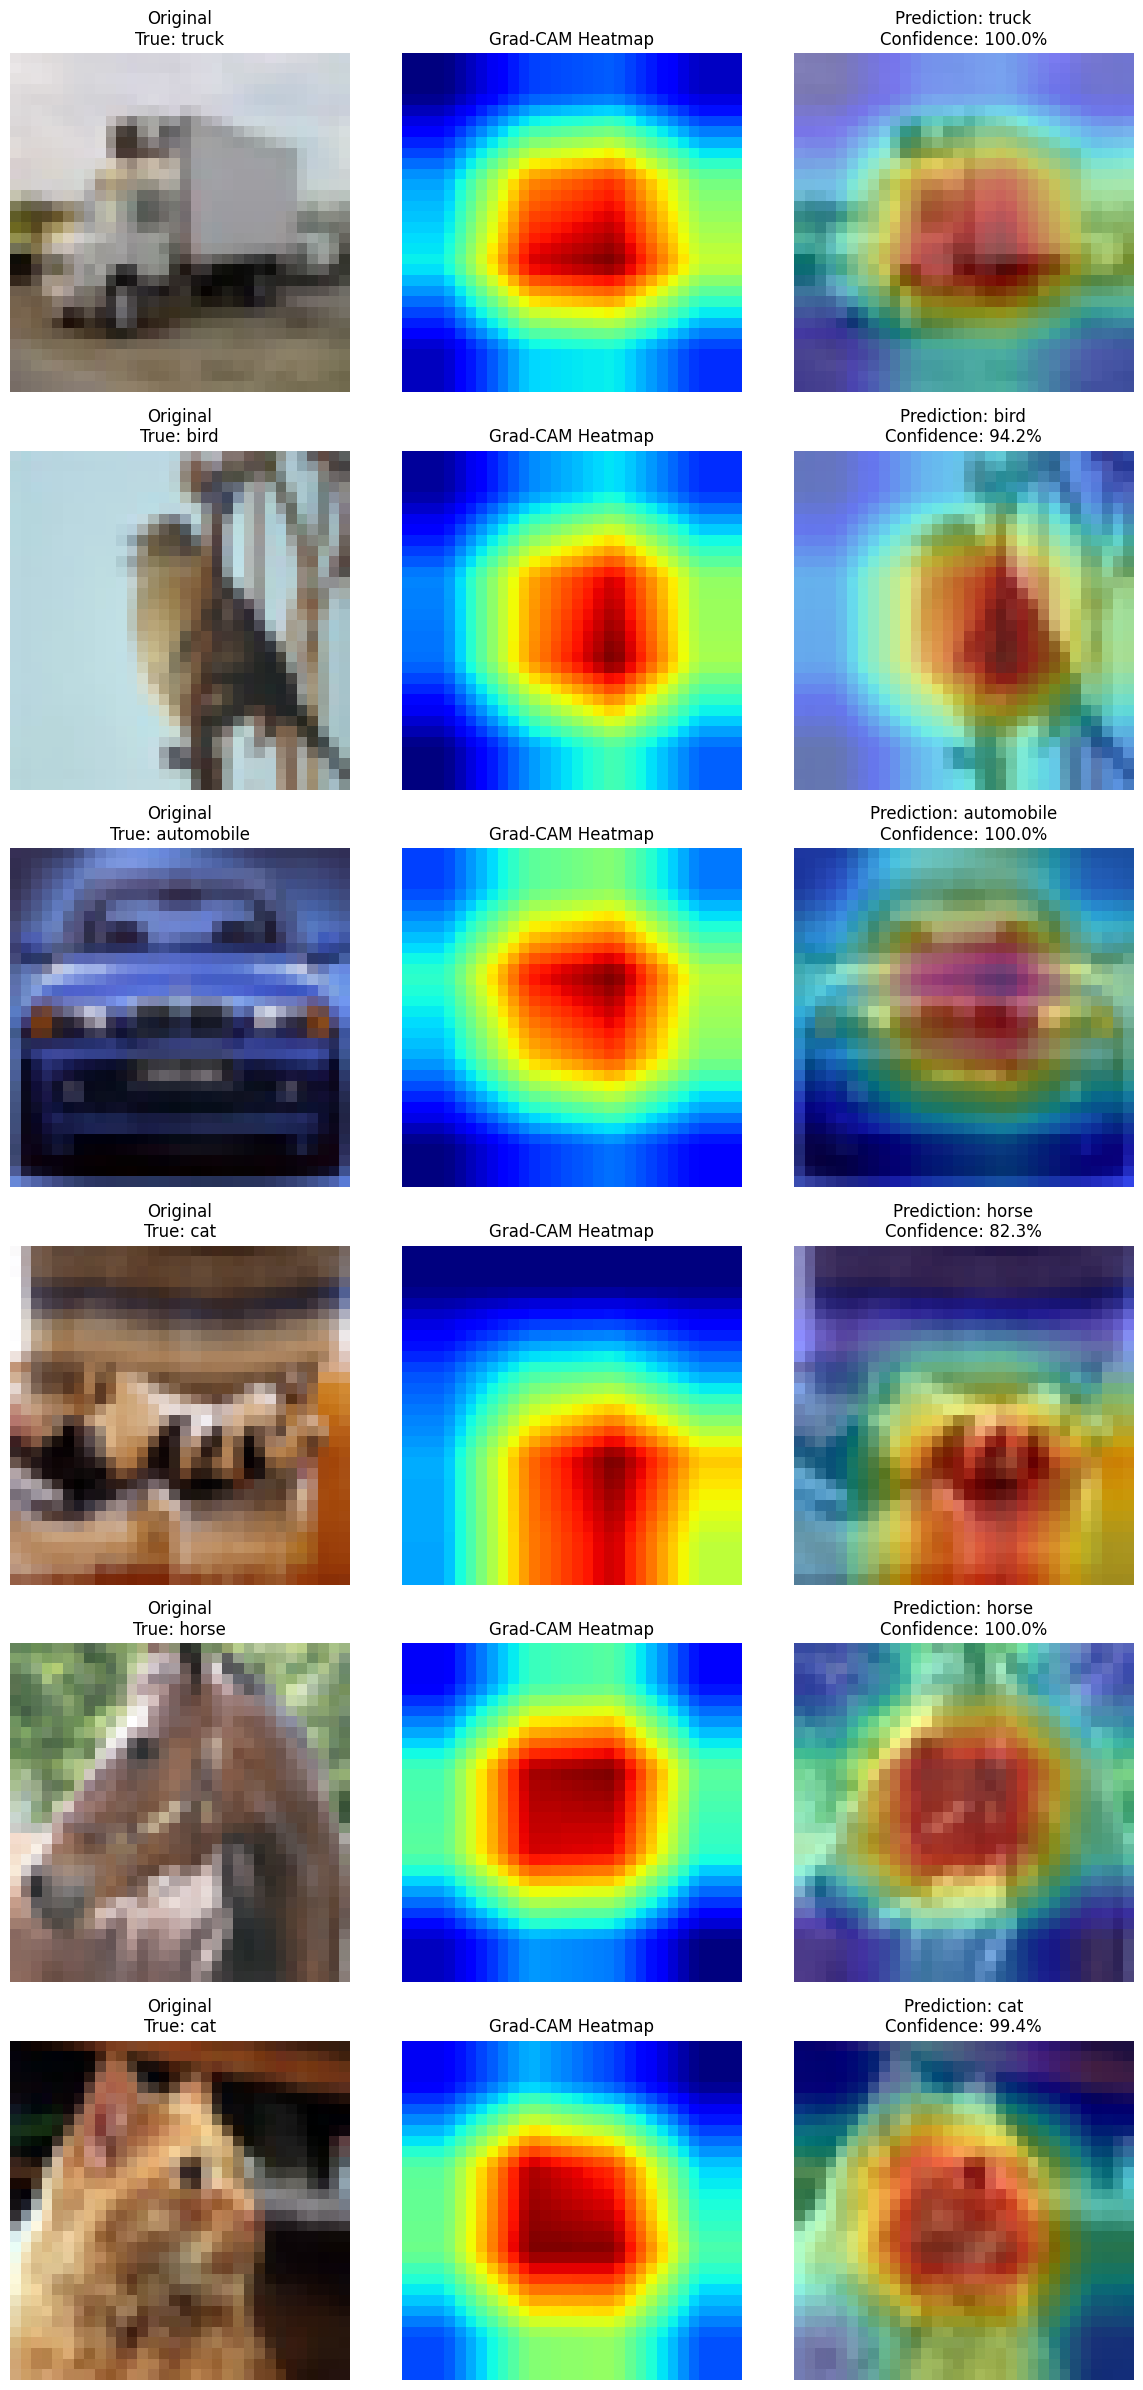

Saved Grad-CAM visualizations to: ./outputs/resnet_gradcam_examples.png


In [46]:
# Cell 46: Display Grad-CAM visualizations

def show_gradcam_examples(model, dataset, gradcam, count=6):
    model.eval()

    indices = random.sample(
        range(len(dataset)),
        min(count, len(dataset))
    )

    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

    fig, axes = plt.subplots(
        len(indices), 3,
        figsize=(12, 4 * len(indices))
    )

    if len(indices) == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, idx in enumerate(indices):
        image, true_label = dataset[idx]
        image_batch = image.unsqueeze(0).to(device)

        heatmap, predicted_class = gradcam.generate(image_batch)

        with torch.no_grad():
            probabilities = torch.softmax(
                model(image_batch), dim=1
            )[0]

        confidence = probabilities[predicted_class].item() * 100

        # Undo ImageNet normalization for display
        original_image = (image.cpu() * std + mean).clamp(0, 1)
        original_image = original_image.permute(1, 2, 0).numpy()

        axes[row, 0].imshow(original_image)
        axes[row, 0].set_title(
            f"Original\nTrue: {classes[true_label]}"
        )

        axes[row, 1].imshow(heatmap, cmap="jet")
        axes[row, 1].set_title("Grad-CAM Heatmap")

        axes[row, 2].imshow(original_image)
        axes[row, 2].imshow(
            heatmap, cmap="jet", alpha=0.45,
            vmin=0, vmax=1
        )
        axes[row, 2].set_title(
            f"Prediction: {classes[predicted_class]}\n"
            f"Confidence: {confidence:.1f}%"
        )

        for ax in axes[row]:
            ax.axis("off")

    plt.tight_layout()

    save_path = os.path.join(OUTPUT_DIR, "resnet_gradcam_examples.png")
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Saved Grad-CAM visualizations to: {save_path}")


show_gradcam_examples(
    resnet_model,
    resnet_test_dataset,
    gradcam,
    count=6
)

In [47]:
# Cell 47: Remove hooks when Grad-CAM is no longer needed

gradcam.close()
print("Grad-CAM hooks removed.")

Grad-CAM hooks removed.


In [48]:
# Cell 48: Select the best model for deployment

validation_results = {
    "Baseline CNN": evaluate_model(
        model, val_loader, criterion, device
    ),
    "Improved CNN": evaluate_model(
        improved_model, val_loader, improved_criterion, device
    ),
    "Pretrained ResNet-18": evaluate_model(
        resnet_model, resnet_val_loader, resnet_criterion, device
    )
}

for name, results in validation_results.items():
    print(
        f"{name}: "
        f"{results['test_accuracy'] * 100:.2f}% validation accuracy"
    )

best_model_name = max(
    validation_results,
    key=lambda name: validation_results[name]["test_accuracy"]
)

model_objects = {
    "Baseline CNN": model,
    "Improved CNN": improved_model,
    "Pretrained ResNet-18": resnet_model
}

normalization_configs = {
    "Baseline CNN": {
        "mean": channel_mean.tolist(),
        "std": channel_std.tolist()
    },
    "Improved CNN": {
        "mean": channel_mean.tolist(),
        "std": channel_std.tolist()
    },
    "Pretrained ResNet-18": {
        "mean": list(IMAGENET_MEAN),
        "std": list(IMAGENET_STD)
    }
}

best_model = model_objects[best_model_name]
best_model.eval()

deployment_checkpoint = {
    "model_name": best_model_name,
    "model_state_dict": best_model.state_dict(),
    "num_classes": num_classes,
    "classes": list(classes),
    "normalization": normalization_configs[best_model_name]
}

deployment_path = os.path.join(
    MODEL_DIR, "deployment_model.pth"
)

torch.save(deployment_checkpoint, deployment_path)

print("\nSelected model:", best_model_name)
print("Saved checkpoint:", deployment_path)

Baseline CNN: 70.36% validation accuracy
Improved CNN: 86.84% validation accuracy
Pretrained ResNet-18: 93.00% validation accuracy

Selected model: Pretrained ResNet-18
Saved checkpoint: ./models/deployment_model.pth


In [49]:
# Cell 49: Save deployment configuration

import json

deployment_config = {
    "model_name": best_model_name,
    "classes": list(classes),
    "normalization": normalization_configs[best_model_name],
    "image_size": 32
}

config_path = os.path.join(
    MODEL_DIR, "deployment_config.json"
)

with open(config_path, "w") as file:
    json.dump(deployment_config, file, indent=4)

print("Saved configuration:", config_path)

print("\nModel files:")
for filename in os.listdir(MODEL_DIR):
    print("-", filename)

Saved configuration: ./models/deployment_config.json

Model files:
- best_cifar10_cnn.pth
- deployment_config.json
- deployment_model.pth
- best_resnet18_cifar10.pth
- best_improved_cifar10_cnn.pth


In [50]:
# Cell 50: Verify the checkpoint can be loaded

loaded_checkpoint = torch.load(
    deployment_path,
    map_location="cpu",
    weights_only=True
)

print("Model:", loaded_checkpoint["model_name"])
print("Number of classes:", loaded_checkpoint["num_classes"])
print("Classes:", loaded_checkpoint["classes"])
print("Normalization:", loaded_checkpoint["normalization"])
print("\nCheckpoint loaded successfully.")

Model: Pretrained ResNet-18
Number of classes: 10
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Normalization: {'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}

Checkpoint loaded successfully.


In [51]:
%%writefile app.py

import streamlit as st
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torchvision.models import resnet18
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import os


# --------------------------------------------------
# 1. Page configuration
# --------------------------------------------------

st.set_page_config(
    page_title="CIFAR-10 Image Classifier",
    page_icon="🖼️",
    layout="wide"
)

st.title("🖼️ CIFAR-10 Image Classification")
st.write(
    "Upload an image to classify it into one of the "
    "10 CIFAR-10 categories."
)


# --------------------------------------------------
# 2. Model architectures
# These must match the notebook architectures.
# --------------------------------------------------

class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)

        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, start_dim=1)

        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))

        return self.fc3(x)


class ImprovedCIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2, 2),
            nn.Dropout2d(0.15)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


def create_model(model_name, num_classes):
    if model_name == "Baseline CNN":
        return CIFAR10CNN(num_classes)

    elif model_name == "Improved CNN":
        return ImprovedCIFAR10CNN(num_classes)

    elif model_name == "Pretrained ResNet-18":
        model = resnet18(weights=None)

        model.conv1 = nn.Conv2d(
            3, 64, kernel_size=3,
            stride=1, padding=1, bias=False
        )

        model.maxpool = nn.Identity()

        model.fc = nn.Linear(
            model.fc.in_features, num_classes
        )

        return model

    else:
        raise ValueError(f"Unknown model: {model_name}")


# --------------------------------------------------
# 3. Load the saved model
# --------------------------------------------------

MODEL_PATH = "models/deployment_model.pth"


@st.cache_resource
def load_model():
    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(
            f"Checkpoint not found: {MODEL_PATH}. "
            "Place deployment_model.pth inside the models folder."
        )

    checkpoint = torch.load(
        MODEL_PATH,
        map_location="cpu",
        weights_only=True
    )

    model_name = checkpoint["model_name"]
    num_classes = checkpoint["num_classes"]
    class_names = checkpoint["classes"]
    normalization = checkpoint["normalization"]

    model = create_model(model_name, num_classes)

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    return model, model_name, class_names, normalization


try:
    model, model_name, classes, normalization = load_model()
except Exception as error:
    st.error(f"Unable to load the model: {error}")
    st.stop()


st.caption(f"Model in use: {model_name}")


# --------------------------------------------------
# 4. Image preprocessing
# --------------------------------------------------

preprocess = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=normalization["mean"],
        std=normalization["std"]
    )
])


# --------------------------------------------------
# 5. Image upload
# --------------------------------------------------

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file).convert("RGB")

        col1, col2 = st.columns(2)

        with col1:
            st.subheader("Uploaded Image")
            st.image(image, use_container_width=True)

        input_tensor = preprocess(image).unsqueeze(0)

        # ------------------------------------------
        # 6. Make prediction
        # ------------------------------------------

        with torch.no_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)[0]

        predicted_index = probabilities.argmax().item()
        predicted_class = classes[predicted_index]
        confidence = probabilities[predicted_index].item()

        with col2:
            st.subheader("Prediction")
            st.success(f"Predicted class: **{predicted_class}**")
            st.metric(
                "Model confidence",
                f"{confidence * 100:.2f}%"
            )

        # ------------------------------------------
        # 7. Top-5 predictions
        # ------------------------------------------

        st.subheader("Top Predictions")

        top_count = min(5, len(classes))
        top_probs, top_indices = torch.topk(
            probabilities, top_count
        )

        prediction_df = pd.DataFrame({
            "Class": [
                classes[index] for index in top_indices.tolist()
            ],
            "Confidence (%)": [
                value * 100 for value in top_probs.tolist()
            ]
        })

        st.bar_chart(
            prediction_df.set_index("Class")["Confidence (%)"]
        )

        st.dataframe(
            prediction_df.round(2),
            use_container_width=True,
            hide_index=True
        )

        st.info(
            "CIFAR-10 contains small 32×32 images. "
            "Images outside this dataset's categories or style "
            "may be classified incorrectly. Confidence is not "
            "a guarantee that a prediction is correct."
        )

    except Exception as error:
        st.error(f"Could not process this image: {error}")

Writing app.py


In [52]:
import os

for path in [
    "app.py",
    "models/deployment_model.pth",
    "models/deployment_config.json"
]:
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"FOUND: {path} ({size_mb:.2f} MB)")
    else:
        print(f"MISSING: {path}")

FOUND: app.py (0.01 MB)
FOUND: models/deployment_model.pth (42.70 MB)
FOUND: models/deployment_config.json (0.00 MB)


In [53]:
%%writefile requirements.txt

streamlit>=1.32,<2.0
torch>=2.2
torchvision>=0.17
pillow>=10.0
pandas>=2.0
matplotlib>=3.7

Writing requirements.txt


In [54]:
%%writefile .gitignore

__pycache__/
*.py[cod]
.ipynb_checkpoints/
.venv/
venv/
.env
.streamlit/secrets.toml
.DS_Store

Writing .gitignore


In [55]:
import os

required_files = [
    "app.py",
    "requirements.txt",
    ".gitignore",
    "models/deployment_model.pth",
    "models/deployment_config.json"
]

print("Deployment preparation checklist\n")

all_found = True

for path in required_files:
    exists = os.path.isfile(path)
    print(f"{'✅' if exists else '❌'} {path}")
    if not exists:
        all_found = False

if all_found:
    print("\nAll required deployment files are present.")
else:
    print("\nSome files are missing. Fix those before continuing.")

Deployment preparation checklist

✅ app.py
✅ requirements.txt
✅ .gitignore
✅ models/deployment_model.pth
✅ models/deployment_config.json

All required deployment files are present.


In [59]:
# Upload the notebook and assemble the complete project

import os
import zipfile
from google.colab import files

print("Upload CIFAR10_Image_Classification.ipynb")
uploaded = files.upload()

notebook_files = [
    name for name in uploaded
    if name.endswith(".ipynb")
]

if not notebook_files:
    raise ValueError("Please upload your .ipynb notebook file.")

notebook_name = notebook_files[0]
print("Notebook received:", notebook_name)

# Include useful checkpoints under GitHub's standard file-size limit.
project_files = [
    notebook_name,
    "app.py",
    "requirements.txt",
    ".gitignore",
    "models/deployment_model.pth",
    "models/deployment_config.json",
    "models/best_cifar10_cnn.pth",
    "models/best_improved_cifar10_cnn.pth",
]

# Include all saved evaluation metrics and visualizations.
for root, dirs, filenames in os.walk("outputs"):
    for filename in filenames:
        project_files.append(os.path.join(root, filename))

zip_path = "cifar10_complete_project.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for path in project_files:
        if os.path.isfile(path):
            size_mb = os.path.getsize(path) / (1024 * 1024)

            if size_mb >= 100:
                print(f"SKIPPED (>100 MB): {path}")
                continue

            zipf.write(path, arcname=path)
            print(f"Added: {path}")
        else:
            print(f"WARNING — file not found: {path}")

print("\nComplete project ZIP created.")
print(f"ZIP size: {os.path.getsize(zip_path) / (1024 * 1024):.2f} MB")

Upload CIFAR10_Image_Classification.ipynb


Saving CIFAR10_Image_Classification.ipynb to CIFAR10_Image_Classification.ipynb
Notebook received: CIFAR10_Image_Classification.ipynb
Added: CIFAR10_Image_Classification.ipynb
Added: app.py
Added: requirements.txt
Added: .gitignore
Added: models/deployment_model.pth
Added: models/deployment_config.json
Added: models/best_cifar10_cnn.pth
Added: models/best_improved_cifar10_cnn.pth
Added: outputs/per_class_accuracy.csv
Added: outputs/per_class_accuracy_comparison.png
Added: outputs/three_model_comparison.csv
Added: outputs/confusion_matrix_validation.png
Added: outputs/validation_classification_report.csv
Added: outputs/three_model_accuracy_comparison.png
Added: outputs/final_test_comparison.csv
Added: outputs/final_test_accuracy_comparison.png
Added: outputs/model_comparison.csv
Added: outputs/three_model_confusion_matrices.png
Added: outputs/model_comparison_accuracy.png
Added: outputs/pixel_distribution.png
Added: outputs/resnet_gradcam_examples.png
Added: outputs/class_distribution.p

In [60]:
from google.colab import files
files.download("cifar10_complete_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>